<a href="https://colab.research.google.com/github/ictnsofu/ICD_5211_Data_Privacy_kampamba_nsofu_202609988/blob/main/202609988_Kampamba_Nsofu_ICD_5211.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ICD 5211 – BIG DATA MANAGEMENT AND PROCESSING

## Individual Assessment: MosiPay's Cross-Border Analytics Challenge

### Q1: Architecting the Privacy-Preserving Host-Data Platform

**Student:** Kampamba Nsofu  
**Programme:** Master of Science in Data Science and Big Data  
**Institution:** Mulungushi University  
**Assessment Period:** 15–18 November 2026  
**Assessment:** Individual Case-Study-Based Google Colab Laboratory

---

# 01 – INTRODUCTION

## 1.1 Assessment Objectives

This laboratory investigates the design of a privacy-preserving data platform for MosiPay, a fictional regional payment-switch analytics provider. The assessment focuses on the responsible management, processing, analysis and controlled disclosure of transaction-host data.

The principal objective is to develop and evaluate an architecture that supports legitimate internal analytical reporting while minimising the exposure of sensitive transaction and account-related information.

The laboratory addresses the following objectives:

1. Profile the supplied transaction-host dataset to establish its structure, data quality, physical characteristics and potential privacy risks.
2. Design a purpose-limited data architecture covering ingestion, quarantine, Bronze, Silver and Gold processing layers, controlled statistical release and data deletion.
3. Develop an executable data contract specifying field-level classifications, validation requirements, permitted purposes, access roles and retention categories.
4. Demonstrate data validation, access restrictions, quarantine decisions and security controls through executable tests.
5. Examine the risks associated with direct identifiers, indirect identifiers, account-level linkage and external information.
6. Document architectural decisions, threats, residual risks and the trade-offs between analytical utility and privacy protection.

## 1.2 Case-Study Background

MosiPay is presented as a regional payment-switch analytics provider working with a South African card-transactions partner. Its Zambian analytics team has been tasked with developing merchant-channel service reports, historical transaction-quality indicators and privacy-preserving statistical summaries.

Management has proposed uploading all 149 fields from the supplied host-data extract into a common analytics lake and distributing filtered CSV files to partner institutions.

This proposal creates potential risks because the source data may contain direct identifiers, account references, transaction-level attributes and contextual information that could be linked with external observations.

The proposed solution therefore separates restricted source-data processing from ordinary analytical access and external statistical disclosure.

The architecture will preserve source-to-derived lineage, enforce role-based access, minimise data collection and exposure, and subject external outputs to privacy and disclosure-risk assessment.

## 1.3 Scope and Assumptions

The investigation uses the supplied synthetic transaction-host dataset, identified as:

`Synthetic_TymeBank_Host_Data_500_Rows.csv`

The assessment describes the dataset as containing 500 records and 149 fields. These dimensions will be independently verified during the data-profiling stage.

The following assumptions and limitations govern the investigation:

1. The dataset is synthetic and is used exclusively for academic experimentation.
2. Field names and observed values do not automatically establish authoritative business meanings.
3. Transaction references, masked card references and account-related fields are not assumed to identify distinct individuals.
4. Currency, amount units, timestamp conventions and status-code meanings will not be inferred without supporting documentation.
5. Security experiments will be conducted locally in the Colab environment using simulated identities and fictional data.
6. AWS and Azure services will be discussed as proposed architectural implementation options. Their inclusion does not imply that either platform has been deployed.
7. Privacy claims will be supported by explicit assumptions, executable tests and documented limitations.
8. The original source file will remain unchanged. All transformations and derived datasets will be stored separately.
9. Raw identifiers, account references and other restricted values will not be included in published evidence or external statistical outputs.

## 1.4 Methodological Approach

The laboratory follows a structured data-engineering and privacy-engineering approach.

The investigation proceeds through data profiling, architectural design, data-contract development, validation and quarantine testing, threat assessment, and the documentation of architectural decisions.

Each technically meaningful experiment will include positive tests demonstrating expected behaviour and negative or adversarial tests examining whether inappropriate behaviour is prevented.

The resulting notebook will provide reproducible evidence of the implemented experiments. Successful execution will not, by itself, be treated as proof of complete confidentiality, anonymity or differential privacy.

## 1.5 Notebook Execution Environment

Google Colab with Python will provide the computational environment. The notebook will be designed for execution from the first cell to the final cell without reliance on manually created variables or previous execution sessions.

The original dataset will be read without modification. Intermediate and derived outputs will be written to a separate working directory.

The notebook will document its software dependencies, input-file requirements and execution assumptions to support reproducibility.


In [1]:

# ============================================================
# 02 – ENVIRONMENT SETUP
# ICD 5211: MosiPay Privacy-Preserving Host-Data Platform
# ============================================================

import sys
import os
import json
import platform
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import numpy as np

# Reproducibility settings
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Working directories
BASE_DIR = Path("/content/mosipay_q1")
INPUT_DIR = BASE_DIR / "input"
OUTPUT_DIR = BASE_DIR / "output"
QUARANTINE_DIR = OUTPUT_DIR / "quarantine"
EVIDENCE_DIR = OUTPUT_DIR / "evidence"

# Create working directories
for directory in [
    INPUT_DIR,
    OUTPUT_DIR,
    QUARANTINE_DIR,
    EVIDENCE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# Environment information
environment = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "random_seed": RANDOM_SEED,
    "execution_time_utc": datetime.now(timezone.utc).isoformat()
}

print("MOSIPAY Q1 ENVIRONMENT INITIALISED")
print("=" * 55)
print(json.dumps(environment, indent=4))
print("\nWorking directory:", BASE_DIR)
print("Input directory:", INPUT_DIR)
print("Output directory:", OUTPUT_DIR)

MOSIPAY Q1 ENVIRONMENT INITIALISED
{
    "python_version": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pandas_version": "2.2.3",
    "numpy_version": "2.4.6",
    "random_seed": 42,
    "execution_time_utc": "2026-11-17T14:46:15.409085+00:00"
}

Working directory: /content/mosipay_q1
Input directory: /content/mosipay_q1/input
Output directory: /content/mosipay_q1/output



# 03 – DATA INGESTION AND SOURCE INTEGRITY

## 3.1 Objective

This section establishes a controlled and reproducible process for loading the supplied transaction-host dataset.

The original CSV is treated as read-only source evidence. Its integrity is verified through a SHA-256 cryptographic hash, while all subsequent processing is performed using a separate in-memory DataFrame and derived output files.

The source file will not be overwritten, modified or silently cleaned during ingestion.

## 3.2 Source File Requirements

The expected source file is:

`Synthetic_TymeBank_Host_Data_500_Rows.csv`

The ingestion process will:

1. Confirm that the source file exists.
2. Calculate its SHA-256 fingerprint.
3. Load the dataset without modifying the source.
4. Record the actual number of records and columns.
5. Display the column names and physical data types.
6. Compare the observed dimensions with the assessment's stated dimensions.


In [2]:

# ============================================================
# 03 – DATA INGESTION AND SOURCE INTEGRITY
# ============================================================

from google.colab import files

# Upload the original CSV
print("Please select Synthetic_TymeBank_Host_Data_500_Rows.csv")

uploaded = files.upload()

# Identify the uploaded CSV
csv_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, but received {len(csv_files)}."
    )

source_filename = csv_files[0]
source_path = INPUT_DIR / source_filename

# Save the uploaded source in the input directory
with open(source_path, "wb") as file:
    file.write(uploaded[source_filename])

# Calculate SHA-256 fingerprint
def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

source_hash_before = calculate_sha256(source_path)

# Load source data as strings to preserve identifier formatting
df = pd.read_csv(
    source_path,
    dtype="string",
    keep_default_na=True,
    low_memory=False
)

# Record source metadata
source_metadata = {
    "filename": source_filename,
    "sha256": source_hash_before,
    "file_size_bytes": source_path.stat().st_size,
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "loaded_at_utc": datetime.now(timezone.utc).isoformat()
}

print("\nSOURCE INGESTION REPORT")
print("=" * 55)
print(json.dumps(source_metadata, indent=4))

print("\nDIMENSION CHECK")
print("Expected dimensions: 500 rows × 149 columns")
print("Observed dimensions:", df.shape)

print("\nSOURCE COLUMN NAMES")
print(df.columns.tolist())

print("\nPHYSICAL DATA TYPES")
print(df.dtypes.to_string())

# Verify the original file has not changed
source_hash_after = calculate_sha256(source_path)

assert source_hash_before == source_hash_after, (
    "Source file integrity check failed."
)

print("\nSource integrity verification: PASSED")

Please select Synthetic_TymeBank_Host_Data_500_Rows.csv


Saving Synthetic_TymeBank_Host_Data_500_Rows.csv to Synthetic_TymeBank_Host_Data_500_Rows.csv

SOURCE INGESTION REPORT
{
    "filename": "Synthetic_TymeBank_Host_Data_500_Rows.csv",
    "sha256": "3db5ef0eecb1a4d8cd163c47d7858815778a9d8c094ffffbf7bbe93984161ed3",
    "file_size_bytes": 307047,
    "rows": 500,
    "columns": 149,
    "loaded_at_utc": "2026-11-17T14:49:29.981643+00:00"
}

DIMENSION CHECK
Expected dimensions: 500 rows × 149 columns
Observed dimensions: (500, 149)

SOURCE COLUMN NAMES
['HPAN', 'ACCT1', 'ACCT1TP', 'ACCT2', 'ACCT2TP', 'ACCT2_CURRENCY', 'ACCTBAL', 'ACCTBAL2', 'ACQINSTCC', 'ACQINSTID', 'ACQ_INST', 'ACQ_SCHM', 'ACTAMT', 'ADDLAMT', 'ADDLDATA', 'ADDRESP', 'ADDRESS_CITY', 'ADDRESS_COUNTRY', 'ADDRESS_NAME', 'ADDRESS_POSTAL_CODE', 'ADDRESS_STATE', 'ADDRESS_STREET', 'ATMID', 'ATM_RPT_DATE', 'AUTHIDRESP', 'AUTH_END', 'AUTH_FLAGS', 'AUTH_START', 'BALANCES', 'BAL_CURRENCY', 'BANK_STTL_DATE', 'BILLS1', 'BILLS2', 'BILLS3', 'BILLS4', 'BITMAP', 'BPC_ADDLDATA', 'CAPTDATE', 


# 04 – DATA PROFILING AND QUALITY ASSESSMENT

## 4.1 Objective

This section examines the structure, completeness, consistency and potential linkability of the 500-record transaction-host dataset.

The profiling exercise establishes the observed physical characteristics of the source fields and identifies potential data-quality and privacy risks.

Particular attention is given to REFNUM, HPAN, ACCT1, ACCT2 and ACCT_NO. These fields will be examined for missingness, repetition and uniqueness without assuming that any of them represents a distinct natural person.

The investigation also examines transaction-level uniqueness and the distributions of transaction response and status fields.

## 4.2 Profiling Principles

The analysis distinguishes between:

- Physical characteristics observed in the CSV.
- Possible business meanings inferred from field names.
- Semantic meanings that remain unverified.
- Privacy conclusions that can and cannot be supported by the available data.

Direct identifier values will not be printed in the profiling evidence. Only statistical summaries and field-level observations will be retained.


In [3]:

# ============================================================
# 04 – DATA PROFILING AND QUALITY ASSESSMENT
# ============================================================

# Confirm that the source DataFrame exists
assert "df" in globals(), "Dataset has not been loaded."
assert df.shape == (500, 149), "Unexpected source dimensions."

print("DATA PROFILING STARTED")
print("=" * 65)

# ------------------------------------------------------------
# 1. GENERAL DATASET SUMMARY
# ------------------------------------------------------------

dataset_summary = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of fields",
        "Total cells",
        "Completely duplicated rows",
        "Fields containing missing values",
        "Fields with no missing values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.size,
        int(df.duplicated().sum()),
        int(df.isna().any().sum()),
        int((~df.isna().any()).sum())
    ]
})

display(dataset_summary)

# ------------------------------------------------------------
# 2. FIELD-LEVEL PROFILE
# ------------------------------------------------------------

field_profile = pd.DataFrame({
    "field": df.columns,
    "physical_dtype": [str(df[c].dtype) for c in df.columns],
    "non_null_count": [int(df[c].notna().sum()) for c in df.columns],
    "null_count": [int(df[c].isna().sum()) for c in df.columns],
    "null_percentage": [
        round(df[c].isna().mean() * 100, 2)
        for c in df.columns
    ],
    "distinct_non_null": [
        int(df[c].nunique(dropna=True))
        for c in df.columns
    ]
})

field_profile["constant_non_null"] = (
    field_profile["distinct_non_null"] <= 1
)

field_profile["all_null"] = (
    field_profile["non_null_count"] == 0
)

print("\nFIELD-LEVEL PROFILE")
display(field_profile)

# ------------------------------------------------------------
# 3. CONSTANT AND ALL-NULL COLUMNS
# ------------------------------------------------------------

constant_columns = field_profile.loc[
    field_profile["constant_non_null"],
    ["field", "non_null_count", "distinct_non_null", "all_null"]
].copy()

print("\nCONSTANT OR ALL-NULL COLUMNS")
display(constant_columns)

# ------------------------------------------------------------
# 4. EXACTLY DUPLICATED COLUMNS
# ------------------------------------------------------------

duplicate_column_pairs = []

columns = list(df.columns)

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if df[columns[i]].equals(df[columns[j]]):
            duplicate_column_pairs.append({
                "column_1": columns[i],
                "column_2": columns[j]
            })

duplicate_columns = pd.DataFrame(
    duplicate_column_pairs,
    columns=["column_1", "column_2"]
)

print("\nEXACTLY DUPLICATED COLUMN PAIRS")
display(duplicate_columns)

# ------------------------------------------------------------
# 5. IDENTIFIER LINKABILITY PROFILE
# ------------------------------------------------------------

candidate_identifiers = [
    "REFNUM",
    "HPAN",
    "ACCT1",
    "ACCT2",
    "ACCT_NO"
]

identifier_results = []

for column in candidate_identifiers:
    if column not in df.columns:
        continue

    non_null = df[column].dropna()
    distinct = non_null.nunique()
    total = len(non_null)

    frequencies = non_null.value_counts()

    identifier_results.append({
        "field": column,
        "non_null_records": total,
        "distinct_values": int(distinct),
        "repeated_value_excess": int(total - distinct),
        "values_repeated": int((frequencies > 1).sum()),
        "maximum_frequency": (
            int(frequencies.max()) if len(frequencies) else 0
        ),
        "uniqueness_percentage": (
            round(distinct / total * 100, 2) if total else 0
        )
    })

identifier_profile = pd.DataFrame(identifier_results)

print("\nIDENTIFIER LINKABILITY PROFILE")
print("No raw identifier values are displayed.")
display(identifier_profile)

# ------------------------------------------------------------
# 6. TRANSACTION-LEVEL UNIQUENESS
# ------------------------------------------------------------

transaction_tests = []

# Test complete-row duplication
transaction_tests.append({
    "test": "Complete row duplication",
    "duplicate_records": int(df.duplicated().sum()),
    "interpretation": (
        "Identical complete rows; requires investigation."
    )
})

# Test candidate reference uniqueness
for column in ["REFNUM", "TRACE", "UTRNNO", "SV_TRACE"]:
    if column in df.columns:
        non_null = df[column].dropna()

        transaction_tests.append({
            "test": f"{column} duplication",
            "duplicate_records": int(non_null.duplicated().sum()),
            "interpretation": (
                "Repeated values do not alone establish replay "
                "or duplicate transactions."
            )
        })

# Test a possible composite transaction reference
composite_fields = [
    "REFNUM",
    "SWITCH_DATE",
    "SWITCH_TIME",
    "TRACE",
    "UTRNNO"
]

available_composite_fields = [
    c for c in composite_fields if c in df.columns
]

if len(available_composite_fields) >= 2:
    complete_composite = df[available_composite_fields].dropna(
        how="any"
    )

    transaction_tests.append({
        "test": "Composite reference duplication",
        "duplicate_records": int(
            complete_composite.duplicated().sum()
        ),
        "interpretation": (
            "Exploratory combination only; not a verified "
            "business transaction key."
        )
    })

transaction_uniqueness = pd.DataFrame(transaction_tests)

print("\nTRANSACTION-LEVEL UNIQUENESS TESTS")
display(transaction_uniqueness)

# ------------------------------------------------------------
# 7. RESPONSE AND STATUS DISTRIBUTIONS
# ------------------------------------------------------------

status_fields = [
    "TRANS_STAT",
    "RESPCODE",
    "RESP",
    "FINAL_STAT",
    "REVERSAL"
]

status_distributions = {}

for column in status_fields:
    if column in df.columns:
        distribution = (
            df[column]
            .fillna("<MISSING>")
            .value_counts(dropna=False)
            .rename_axis("observed_value")
            .reset_index(name="record_count")
        )

        status_distributions[column] = distribution

        print(f"\nDISTRIBUTION: {column}")
        display(distribution)

# ------------------------------------------------------------
# 8. SAVE PROFILING EVIDENCE
# ------------------------------------------------------------

field_profile.to_csv(
    EVIDENCE_DIR / "Q1_Field_Profile.csv",
    index=False
)

dataset_summary.to_csv(
    EVIDENCE_DIR / "Q1_Dataset_Summary.csv",
    index=False
)

constant_columns.to_csv(
    EVIDENCE_DIR / "Q1_Constant_Columns.csv",
    index=False
)

duplicate_columns.to_csv(
    EVIDENCE_DIR / "Q1_Duplicate_Columns.csv",
    index=False
)

identifier_profile.to_csv(
    EVIDENCE_DIR / "Q1_Identifier_Profile.csv",
    index=False
)

transaction_uniqueness.to_csv(
    EVIDENCE_DIR / "Q1_Transaction_Uniqueness.csv",
    index=False
)

for field, distribution in status_distributions.items():
    distribution.to_csv(
        EVIDENCE_DIR / f"Q1_{field}_Distribution.csv",
        index=False
    )

print("\nPROFILING COMPLETE")
print("Evidence directory:", EVIDENCE_DIR)
print("Original source DataFrame was not modified.")

DATA PROFILING STARTED


,Metric,Value
0,Number of records,500
1,Number of fields,149
2,Total cells,74500
3,Completely duplicated rows,0
4,Fields containing missing values,34
5,Fields with no missing values,115



FIELD-LEVEL PROFILE


,field,physical_dtype,non_null_count,null_count,null_percentage,distinct_non_null,constant_non_null,all_null
0,HPAN,string,500,0,0.0,157,False,False
1,ACCT1,string,500,0,0.0,157,False,False
2,ACCT1TP,string,500,0,0.0,1,True,False
3,ACCT2,string,0,500,100.0,0,True,True
4,ACCT2TP,string,500,0,0.0,1,True,False
...,...,...,...,...,...,...,...,...
144,TRANS_TYPE,string,500,0,0.0,7,False,False
145,TTIME,string,500,0,0.0,497,False,False
146,UDATE,string,500,0,0.0,42,False,False
147,UTRNNO,string,500,0,0.0,500,False,False



CONSTANT OR ALL-NULL COLUMNS


,field,non_null_count,distinct_non_null,all_null
2,ACCT1TP,500,1,False
3,ACCT2,0,0,True
4,ACCT2TP,500,1,False
5,ACCT2_CURRENCY,500,1,False
7,ACCTBAL2,500,1,False
...,...,...,...,...
135,SYSRATE,500,1,False
136,SYS_CURRENCY,500,1,False
137,TDATE,500,1,False
141,TRACK1,0,0,True


... (13 outputs left out)

,observed_value,record_count
0,<MISSING>,500



DISTRIBUTION: REVERSAL


,observed_value,record_count
0,0,482
1,1,18



PROFILING COMPLETE
Evidence directory: /content/mosipay_q1/output/evidence
Original source DataFrame was not modified.


In [4]:

# ============================================================
# 04.1 – REFINED DATA QUALITY AND LINKAGE INVESTIGATION
# ============================================================

print("REFINED DATA QUALITY INVESTIGATION")
print("=" * 65)

# 1. Complete list of fields containing missing values
missing_fields = field_profile.loc[
    field_profile["null_count"] > 0,
    ["field", "null_count", "null_percentage"]
].sort_values(
    "null_percentage", ascending=False
).reset_index(drop=True)

print("\nA. ALL FIELDS CONTAINING MISSING VALUES")
display(missing_fields)

# 2. Separate all-null and partially missing fields
all_null_fields = field_profile.loc[
    field_profile["all_null"],
    ["field", "null_count"]
].reset_index(drop=True)

partially_missing_fields = field_profile.loc[
    (field_profile["null_count"] > 0) &
    (~field_profile["all_null"]),
    ["field", "null_count", "null_percentage"]
].sort_values(
    "null_percentage", ascending=False
).reset_index(drop=True)

print("\nB. ALL-NULL FIELDS")
display(all_null_fields)

print("\nC. PARTIALLY MISSING FIELDS")
display(partially_missing_fields)

# 3. Separate constant fields from all-null fields
non_null_constant_fields = field_profile.loc[
    (field_profile["constant_non_null"]) &
    (~field_profile["all_null"]),
    ["field", "non_null_count", "distinct_non_null"]
].reset_index(drop=True)

print("\nD. NON-NULL CONSTANT FIELDS")
display(non_null_constant_fields)

# 4. Find exact duplicate columns with meaningful variation
# Exclude all-null and constant columns from this comparison.
variable_columns = field_profile.loc[
    field_profile["distinct_non_null"] > 1,
    "field"
].tolist()

meaningful_duplicate_pairs = []

for i in range(len(variable_columns)):
    for j in range(i + 1, len(variable_columns)):
        col_a = variable_columns[i]
        col_b = variable_columns[j]

        if df[col_a].equals(df[col_b]):
            meaningful_duplicate_pairs.append({
                "column_1": col_a,
                "column_2": col_b
            })

meaningful_duplicates = pd.DataFrame(
    meaningful_duplicate_pairs,
    columns=["column_1", "column_2"]
)

print("\nE. EXACT DUPLICATES AMONG VARIABLE COLUMNS")
display(meaningful_duplicates)

# 5. Investigate identifier relationships without printing values
identifier_pairs = [
    ("HPAN", "ACCT1"),
    ("HPAN", "ACCT_NO"),
    ("ACCT1", "ACCT_NO")
]

identifier_relationships = []

for col_a, col_b in identifier_pairs:
    if col_a in df.columns and col_b in df.columns:
        identifier_relationships.append({
            "field_1": col_a,
            "field_2": col_b,
            "exactly_equal": bool(df[col_a].equals(df[col_b])),
            "same_null_pattern": bool(
                df[col_a].isna().equals(df[col_b].isna())
            ),
            "matching_records": int(
                (df[col_a] == df[col_b]).fillna(False).sum()
            ),
            "distinct_values_field_1": int(df[col_a].nunique()),
            "distinct_values_field_2": int(df[col_b].nunique())
        })

identifier_relationships = pd.DataFrame(identifier_relationships)

print("\nF. IDENTIFIER FIELD RELATIONSHIPS")
display(identifier_relationships)

# 6. Account-reference frequency summary
# Do not display actual account or card references.
for col in ["HPAN", "ACCT1", "ACCT_NO"]:
    if col in df.columns:
        frequencies = df[col].value_counts(dropna=True)

        print(f"\nG. FREQUENCY SUMMARY: {col}")
        print({
            "distinct_references": int(len(frequencies)),
            "references_appearing_once": int((frequencies == 1).sum()),
            "references_appearing_more_than_once": int((frequencies > 1).sum()),
            "maximum_transactions_per_reference": (
                int(frequencies.max()) if len(frequencies) else 0
            ),
            "median_transactions_per_reference": (
                float(frequencies.median()) if len(frequencies) else 0
            )
        })

# 7. Save refined evidence
missing_fields.to_csv(
    EVIDENCE_DIR / "Q1_Missing_Fields.csv", index=False
)

all_null_fields.to_csv(
    EVIDENCE_DIR / "Q1_All_Null_Fields.csv", index=False
)

partially_missing_fields.to_csv(
    EVIDENCE_DIR / "Q1_Partially_Missing_Fields.csv", index=False
)

non_null_constant_fields.to_csv(
    EVIDENCE_DIR / "Q1_Non_Null_Constant_Fields.csv", index=False
)

meaningful_duplicates.to_csv(
    EVIDENCE_DIR / "Q1_Meaningful_Duplicate_Columns.csv", index=False
)

identifier_relationships.to_csv(
    EVIDENCE_DIR / "Q1_Identifier_Relationships.csv", index=False
)

print("\nREFINED INVESTIGATION COMPLETED")
print("Evidence saved to:", EVIDENCE_DIR)

REFINED DATA QUALITY INVESTIGATION

A. ALL FIELDS CONTAINING MISSING VALUES


,field,null_count,null_percentage
0,ACCT2,500,100.0
1,ADDLAMT,500,100.0
2,ADDLDATA,500,100.0
3,ADDRESS_POSTAL_CODE,500,100.0
4,ADDRESS_STATE,500,100.0
5,ADDRESS_STREET,500,100.0
6,BITMAP,500,100.0
7,ATM_RPT_DATE,500,100.0
8,CARDACCIDC,500,100.0
9,BPC_ADDLDATA,500,100.0



B. ALL-NULL FIELDS


,field,null_count
0,ACCT2,500
1,ADDLAMT,500
2,ADDLDATA,500
3,ADDRESS_POSTAL_CODE,500
4,ADDRESS_STATE,500
5,ADDRESS_STREET,500
6,ATM_RPT_DATE,500
7,BITMAP,500
8,BPC_ADDLDATA,500
9,CARDACCIDC,500



C. PARTIALLY MISSING FIELDS


,field,null_count,null_percentage
0,ADDRESP,351,70.2
1,AUTHIDRESP,131,26.2


... (3 outputs left out)

,column_1,column_2
0,ACCT1,ACCT_NO
1,ACTAMT,CONAMT
2,ACTAMT,INSTITAMT
3,ACTAMT,REQAMT
4,ACTAMT,SYSAMT
5,BANK_STTL_DATE,CAPTDATE
6,BANK_STTL_DATE,SWITCH_DATE
7,BANK_STTL_DATE,UDATE
8,CAPTDATE,SWITCH_DATE
9,CAPTDATE,UDATE



F. IDENTIFIER FIELD RELATIONSHIPS


,field_1,field_2,exactly_equal,same_null_pattern,matching_records,distinct_values_field_1,distinct_values_field_2
0,HPAN,ACCT1,False,True,0,157,157
1,HPAN,ACCT_NO,False,True,0,157,157
2,ACCT1,ACCT_NO,True,True,500,157,157



G. FREQUENCY SUMMARY: HPAN
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

G. FREQUENCY SUMMARY: ACCT1
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

G. FREQUENCY SUMMARY: ACCT_NO
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

REFINED INVESTIGATION COMPLETED
Evidence saved to: /content/mosipay_q1/output/evidence



## 4.3 Data Profiling Results and Interpretation

The supplied dataset was successfully loaded and profiled. The observed dimensions were 500 records and 149 fields, producing 74,500 individual data cells.

No completely duplicated rows were identified. However, 34 fields contained missing values, comprising 32 entirely null fields and two partially missing fields. ADDRESP had 70.2% missing values, while AUTHIDRESP had 26.2% missing values.

The investigation identified 72 non-null constant fields and 32 all-null fields. Consequently, 104 of the 149 source fields had no variation in the current extract.

A refined duplicate-column investigation identified 21 exact duplicate pairs among variable columns. Notable relationships included ACCT1 and ACCT_NO, which were identical across all 500 records. ACTAMT, CONAMT, INSTITAMT, REQAMT and SYSAMT also contained identical observed values. Several date and time fields exhibited similar relationships. These observations indicate structural redundancy, but do not establish that the respective fields have identical business meanings.

The identifier investigation found 500 distinct REFNUM values. HPAN, ACCT1 and ACCT_NO each contained 157 distinct values. There were 136 references appearing more than once, with a maximum frequency of nine records and a median frequency of three records per reference.

ACCT1 and ACCT_NO were exactly equal, whereas HPAN was not equal to either field. Equal distinct-value counts therefore did not establish equality or a verified one-to-one relationship between the fields.

The transaction-status distribution contained 369 SUCCESS records (73.8%) and 131 DECLINED records (26.2%). RESPCODE contained five observed categories: 00, 51, 05, 96 and 55. REVERSAL contained 482 records with value 0 and 18 records with value 1. These are observed distributions; authoritative business interpretations of the codes remain outstanding. FINAL_STAT was entirely null.

### 4.4 Privacy and Data-Quality Implications

The uniqueness of REFNUM establishes only reference uniqueness within the supplied extract. It does not establish unique transaction subjects or distinct natural persons.

Repeated HPAN, ACCT1 and ACCT_NO values indicate potential card/account-level linkage across transactions. However, an account may be associated with more than one person, and one person may hold multiple accounts or cards. The dataset therefore does not provide a verified count of distinct privacy subjects.

The presence of duplicate fields and extensive non-variation also supports data minimisation. The proposed processing architecture should select fields according to documented analytical purposes, preserve raw-to-derived lineage, and restrict direct identifiers to authorised processing services.

### 4.5 Profiling Limitations

The dataset does not include an authoritative field dictionary or verified person-level identifier. The currency and scale of monetary fields, timestamp conventions and meanings of response codes remain uncertain.

Consequently, the profiling results are descriptive findings about the supplied extract and should not be interpreted as verified operational characteristics of an actual financial institution.



# 05 – PRIVACY-PRESERVING DATA PLATFORM ARCHITECTURE

## 5.1 Architectural Objective

This section proposes an end-to-end privacy-preserving data architecture for MosiPay. The architecture replaces the proposed common analytics lake and email distribution of filtered transaction-level CSV files with a controlled data lifecycle.

The design separates restricted source records from minimised analytical datasets and approved statistical outputs. It incorporates data validation, quarantine, encryption, role-based access, tokenisation, audit logging, retention management and controlled disclosure.

The architecture is a proposed design for the case study. AWS and Azure service mappings are architectural alternatives and are not representations of deployed infrastructure.


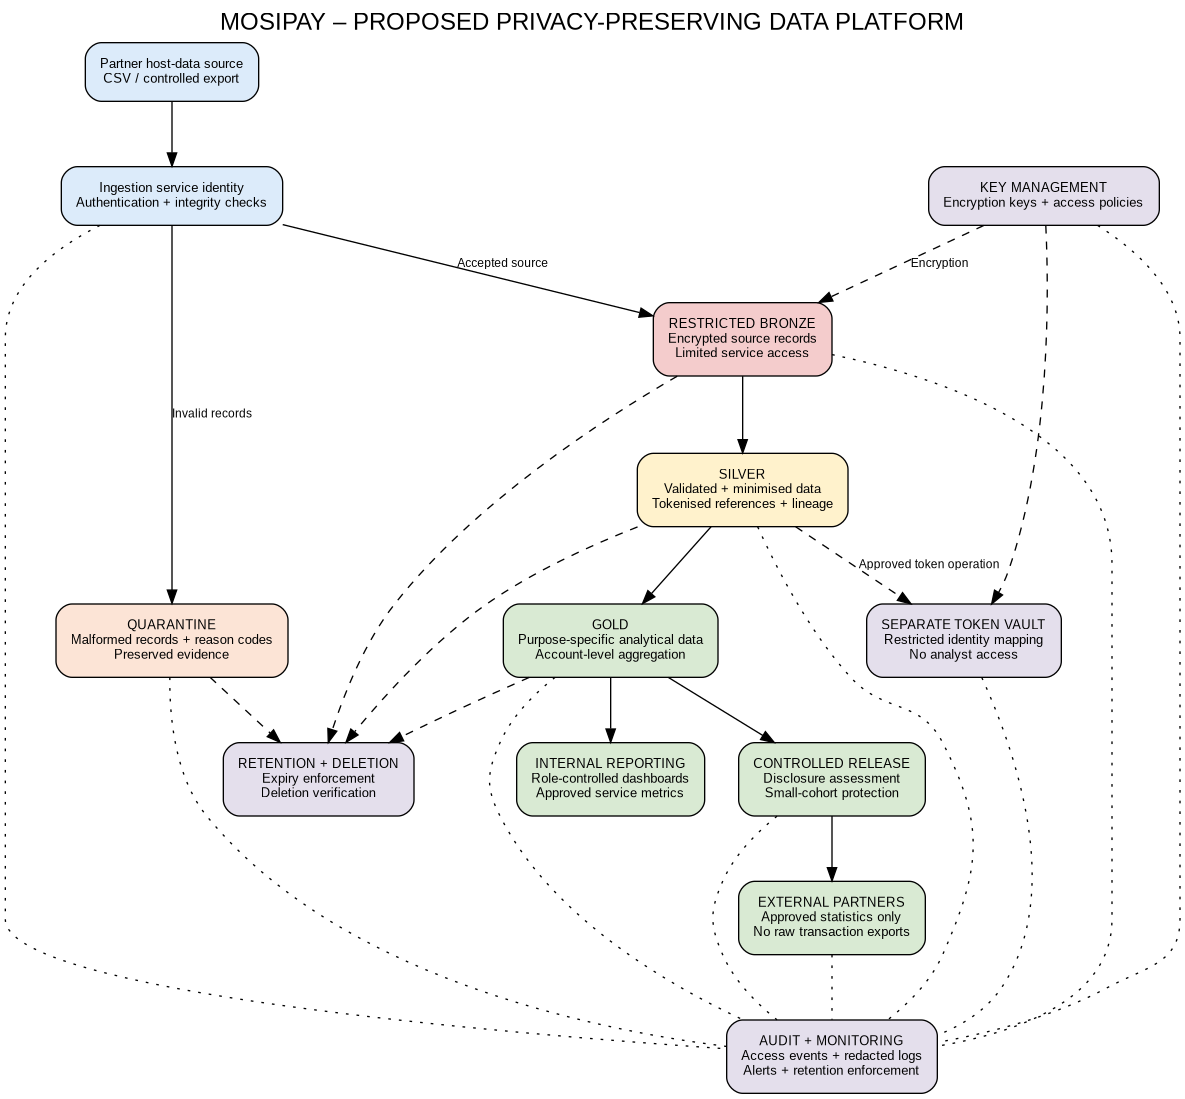

Architecture diagram saved:
/content/mosipay_q1/output/Q1_MosiPay_Architecture.png


In [5]:

# ============================================================
# 05.2 – END-TO-END ARCHITECTURE DIAGRAM
# ============================================================

!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display, Image

architecture = Digraph(
    "MosiPay_Privacy_Architecture",
    format="png"
)

architecture.attr(
    rankdir="TB",
    label="MOSIPAY – PROPOSED PRIVACY-PRESERVING DATA PLATFORM",
    labelloc="t",
    fontsize="18",
    fontname="Arial",
    ranksep="0.65",
    nodesep="0.35"
)

architecture.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="10",
    margin="0.15"
)

architecture.attr(
    "edge",
    fontname="Arial",
    fontsize="9"
)

# Source and ingestion
architecture.node(
    "source",
    "Partner host-data source\nCSV / controlled export",
    fillcolor="#DCEBFA"
)

architecture.node(
    "ingestion",
    "Ingestion service identity\nAuthentication + integrity checks",
    fillcolor="#DCEBFA"
)

architecture.node(
    "quarantine",
    "QUARANTINE\nMalformed records + reason codes\nPreserved evidence",
    fillcolor="#FCE4D6"
)

# Data lifecycle
architecture.node(
    "bronze",
    "RESTRICTED BRONZE\nEncrypted source records\nLimited service access",
    fillcolor="#F4CCCC"
)

architecture.node(
    "silver",
    "SILVER\nValidated + minimised data\nTokenised references + lineage",
    fillcolor="#FFF2CC"
)

architecture.node(
    "gold",
    "GOLD\nPurpose-specific analytical data\nAccount-level aggregation",
    fillcolor="#D9EAD3"
)

# Outputs
architecture.node(
    "internal",
    "INTERNAL REPORTING\nRole-controlled dashboards\nApproved service metrics",
    fillcolor="#D9EAD3"
)

architecture.node(
    "release",
    "CONTROLLED RELEASE\nDisclosure assessment\nSmall-cohort protection",
    fillcolor="#D9EAD3"
)

architecture.node(
    "external",
    "EXTERNAL PARTNERS\nApproved statistics only\nNo raw transaction exports",
    fillcolor="#D9EAD3"
)

# Security boundary
architecture.node(
    "vault",
    "SEPARATE TOKEN VAULT\nRestricted identity mapping\nNo analyst access",
    fillcolor="#E4DFEC"
)

architecture.node(
    "kms",
    "KEY MANAGEMENT\nEncryption keys + access policies",
    fillcolor="#E4DFEC"
)

architecture.node(
    "audit",
    "AUDIT + MONITORING\nAccess events + redacted logs\nAlerts + retention enforcement",
    fillcolor="#E4DFEC"
)

architecture.node(
    "deletion",
    "RETENTION + DELETION\nExpiry enforcement\nDeletion verification",
    fillcolor="#E4DFEC"
)

# Lifecycle connections
architecture.edge("source", "ingestion")
architecture.edge("ingestion", "quarantine", label="Invalid records")
architecture.edge("ingestion", "bronze", label="Accepted source")
architecture.edge("bronze", "silver")
architecture.edge("silver", "gold")
architecture.edge("gold", "internal")
architecture.edge("gold", "release")
architecture.edge("release", "external")

# Security and governance relationships
architecture.edge(
    "silver",
    "vault",
    label="Approved token operation",
    style="dashed"
)

architecture.edge(
    "kms",
    "bronze",
    label="Encryption",
    style="dashed"
)

architecture.edge(
    "kms",
    "vault",
    style="dashed"
)

for node in [
    "ingestion", "quarantine", "bronze", "silver",
    "gold", "release", "vault", "kms", "external"
]:
    architecture.edge(
        node,
        "audit",
        style="dotted",
        arrowhead="none"
    )

architecture.edge("bronze", "deletion", style="dashed")
architecture.edge("silver", "deletion", style="dashed")
architecture.edge("gold", "deletion", style="dashed")
architecture.edge("quarantine", "deletion", style="dashed")

# Render diagram
architecture_path = str(
    OUTPUT_DIR / "Q1_MosiPay_Architecture"
)

architecture.render(
    architecture_path,
    cleanup=True
)

display(Image(filename=architecture_path + ".png"))

print("Architecture diagram saved:")
print(architecture_path + ".png")

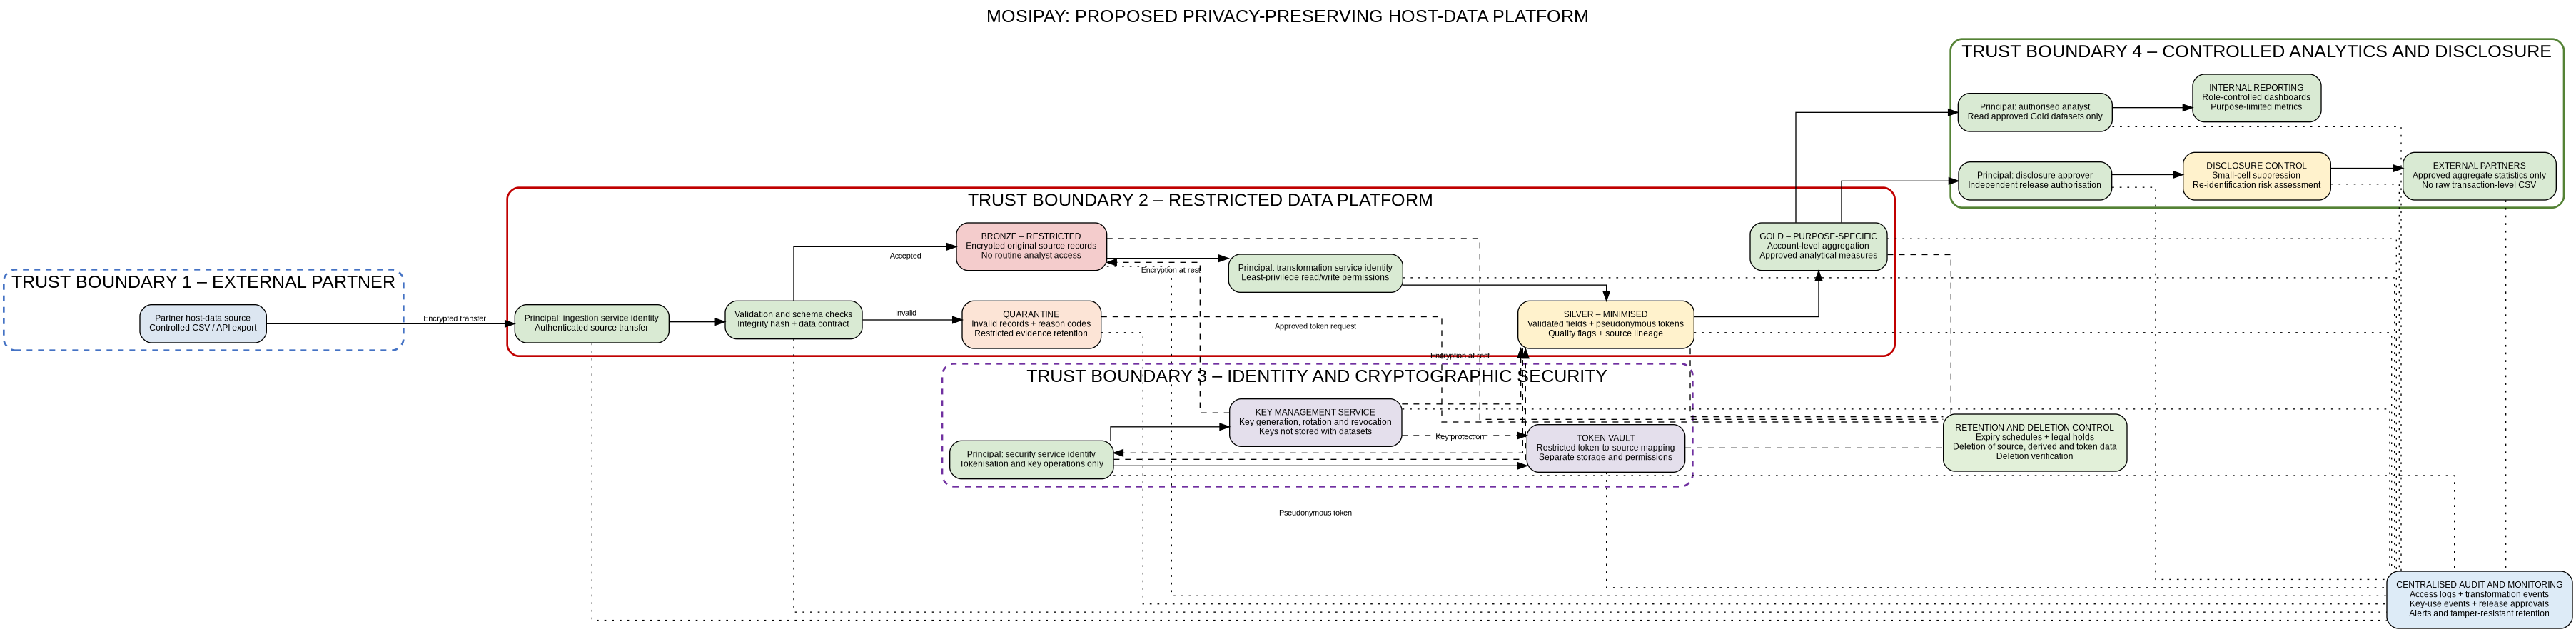

Enhanced architecture saved:
/content/mosipay_q1/output/Q1_MosiPay_Architecture_Enhanced.png


In [6]:

# ============================================================
# 05.2 – ENHANCED ARCHITECTURE WITH TRUST BOUNDARIES
# ============================================================

from graphviz import Digraph
from IPython.display import display, Image

architecture = Digraph(
    "MosiPay_Enhanced_Privacy_Architecture",
    format="png"
)

architecture.attr(
    rankdir="LR",
    label="MOSIPAY: PROPOSED PRIVACY-PRESERVING HOST-DATA PLATFORM",
    labelloc="t",
    fontsize="19",
    fontname="Arial",
    ranksep="0.8",
    nodesep="0.45",
    compound="true",
    splines="ortho"
)

architecture.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="9",
    margin="0.14"
)

architecture.attr("edge", fontname="Arial", fontsize="8")

# ------------------------------------------------------------
# TRUST BOUNDARY 1: EXTERNAL SOURCE
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_source") as source:
    source.attr(
        label="TRUST BOUNDARY 1 – EXTERNAL PARTNER",
        style="rounded,dashed",
        color="#4472C4",
        penwidth="2"
    )

    source.node(
        "partner",
        "Partner host-data source\nControlled CSV / API export",
        fillcolor="#DCE6F1"
    )

# ------------------------------------------------------------
# TRUST BOUNDARY 2: RESTRICTED DATA PLATFORM
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_data") as data:
    data.attr(
        label="TRUST BOUNDARY 2 – RESTRICTED DATA PLATFORM",
        style="rounded",
        color="#C00000",
        penwidth="2"
    )

    data.node(
        "ingest_identity",
        "Principal: ingestion service identity\nAuthenticated source transfer",
        fillcolor="#D9EAD3"
    )

    data.node(
        "validation",
        "Validation and schema checks\nIntegrity hash + data contract",
        fillcolor="#D9EAD3"
    )

    data.node(
        "quarantine",
        "QUARANTINE\nInvalid records + reason codes\nRestricted evidence retention",
        fillcolor="#FCE4D6"
    )

    data.node(
        "bronze",
        "BRONZE – RESTRICTED\nEncrypted original source records\nNo routine analyst access",
        fillcolor="#F4CCCC"
    )

    data.node(
        "pipeline_identity",
        "Principal: transformation service identity\nLeast-privilege read/write permissions",
        fillcolor="#D9EAD3"
    )

    data.node(
        "silver",
        "SILVER – MINIMISED\nValidated fields + pseudonymous tokens\nQuality flags + source lineage",
        fillcolor="#FFF2CC"
    )

    data.node(
        "gold",
        "GOLD – PURPOSE-SPECIFIC\nAccount-level aggregation\nApproved analytical measures",
        fillcolor="#D9EAD3"
    )

    data.edge("ingest_identity", "validation")
    data.edge("validation", "quarantine", label="Invalid")
    data.edge("validation", "bronze", label="Accepted")
    data.edge("bronze", "pipeline_identity")
    data.edge("pipeline_identity", "silver")
    data.edge("silver", "gold")

# ------------------------------------------------------------
# TRUST BOUNDARY 3: TOKEN VAULT AND KEY MANAGEMENT
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_security") as security:
    security.attr(
        label="TRUST BOUNDARY 3 – IDENTITY AND CRYPTOGRAPHIC SECURITY",
        style="rounded,dashed",
        color="#7030A0",
        penwidth="2"
    )

    security.node(
        "vault",
        "TOKEN VAULT\nRestricted token-to-source mapping\nSeparate storage and permissions",
        fillcolor="#E4DFEC"
    )

    security.node(
        "kms",
        "KEY MANAGEMENT SERVICE\nKey generation, rotation and revocation\nKeys not stored with datasets",
        fillcolor="#E4DFEC"
    )

    security.node(
        "security_identity",
        "Principal: security service identity\nTokenisation and key operations only",
        fillcolor="#D9EAD3"
    )

    security.edge("security_identity", "vault")
    security.edge("security_identity", "kms")

# ------------------------------------------------------------
# TRUST BOUNDARY 4: ANALYTICS AND CONTROLLED DISCLOSURE
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_release") as release:
    release.attr(
        label="TRUST BOUNDARY 4 – CONTROLLED ANALYTICS AND DISCLOSURE",
        style="rounded",
        color="#548235",
        penwidth="2"
    )

    release.node(
        "analyst",
        "Principal: authorised analyst\nRead approved Gold datasets only",
        fillcolor="#D9EAD3"
    )

    release.node(
        "internal",
        "INTERNAL REPORTING\nRole-controlled dashboards\nPurpose-limited metrics",
        fillcolor="#D9EAD3"
    )

    release.node(
        "approver",
        "Principal: disclosure approver\nIndependent release authorisation",
        fillcolor="#D9EAD3"
    )

    release.node(
        "release",
        "DISCLOSURE CONTROL\nSmall-cell suppression\nRe-identification risk assessment",
        fillcolor="#FFF2CC"
    )

    release.node(
        "external",
        "EXTERNAL PARTNERS\nApproved aggregate statistics only\nNo raw transaction-level CSV",
        fillcolor="#D9EAD3"
    )

    release.edge("gold", "analyst")
    release.edge("analyst", "internal")
    release.edge("gold", "approver")
    release.edge("approver", "release")
    release.edge("release", "external")

# ------------------------------------------------------------
# GOVERNANCE AND AUDIT SERVICES
# ------------------------------------------------------------

architecture.node(
    "audit",
    "CENTRALISED AUDIT AND MONITORING\nAccess logs + transformation events\nKey-use events + release approvals\nAlerts and tamper-resistant retention",
    fillcolor="#DDEBF7"
)

architecture.node(
    "retention",
    "RETENTION AND DELETION CONTROL\nExpiry schedules + legal holds\nDeletion of source, derived and token data\nDeletion verification",
    fillcolor="#E2F0D9"
)

# ------------------------------------------------------------
# CROSS-BOUNDARY DATA FLOWS
# ------------------------------------------------------------

architecture.edge("partner", "ingest_identity",
                  label="Encrypted transfer")

architecture.edge("silver", "security_identity",
                  label="Approved token request",
                  style="dashed")

architecture.edge("security_identity", "silver",
                  label="Pseudonymous token",
                  style="dashed")

architecture.edge("kms", "bronze",
                  label="Encryption at rest",
                  style="dashed")

architecture.edge("kms", "silver",
                  label="Encryption at rest",
                  style="dashed")

architecture.edge("kms", "vault",
                  label="Key protection",
                  style="dashed")

# Audit events from all important stages
for node in [
    "ingest_identity", "validation", "quarantine", "bronze",
    "pipeline_identity", "silver", "gold", "security_identity",
    "vault", "kms", "analyst", "approver", "release", "external"
]:
    architecture.edge(
        node,
        "audit",
        style="dotted",
        arrowhead="none"
    )

# Retention and deletion apply to all data-bearing layers
for node in ["quarantine", "bronze", "silver", "gold", "vault"]:
    architecture.edge(
        node,
        "retention",
        style="dashed",
        arrowhead="none"
    )

# Render and display
architecture_path = str(
    OUTPUT_DIR / "Q1_MosiPay_Architecture_Enhanced"
)

architecture.render(
    architecture_path,
    cleanup=True
)

display(Image(filename=architecture_path + ".png"))

print("Enhanced architecture saved:")
print(architecture_path + ".png")


## 5.3 Trust Boundaries and Principal Identities

The proposed architecture establishes four distinct trust boundaries.

**Boundary 1 – External partner environment**

The partner host-data source is outside MosiPay's direct security control. Data is transferred through an authenticated and encrypted channel. The receiving ingestion service verifies the source, file integrity and expected schema before accepting the data.

**Boundary 2 – Restricted data platform**

The ingestion service writes accepted records to the restricted Bronze layer. Records failing validation are directed to quarantine, together with their validation errors and relevant evidence. Quarantined records are retained under restricted permissions for investigation and are not silently discarded.

A separate transformation service identity reads authorised Bronze records and performs validation, minimisation and tokenisation before writing the Silver layer. Analysts do not receive direct access to the raw Bronze data.

The Gold layer contains purpose-specific analytical datasets. Account-level aggregation is performed during the controlled Silver-to-Gold transformation. Where account-level grouping is required, a pseudonymous reference is used. The identifying token should not be included in externally released aggregate outputs.

**Boundary 3 – Token vault and cryptographic security**

The token vault is logically and administratively separated from the analytical data stores. It contains the restricted mapping between original identifiers and their pseudonymous tokens.

Only an authorised tokenisation service identity can request approved tokenisation or detokenisation operations. Analysts and external partners cannot access the token vault.

Encryption keys are managed separately from the datasets. Keys are not stored in source files, notebooks, configuration files or ordinary data-storage locations. Key access, rotation and revocation are controlled through a dedicated key-management service.

**Boundary 4 – Controlled analytics and disclosure**

Authorised analysts access approved Gold datasets through role-controlled reporting services. Internal reporting is limited to approved analytical purposes.

External disclosure requires an independent approval process. Before release, outputs undergo disclosure-risk assessment, including small-cell suppression and consideration of whether combinations of released statistics could reveal an individual or account.

External partners receive approved aggregate statistics rather than transaction-level source records.

### Principal identities and permissions

The architecture uses separate non-human service identities and human user roles.

| Principal identity | Permitted activity | Prohibited activity |
|---|---|---|
| Ingestion service identity | Receive source data, verify integrity and write accepted records to Bronze | Read token vault or release data externally |
| Transformation service identity | Read authorised Bronze records, validate and write Silver/Gold outputs | Administer keys or approve external disclosure |
| Tokenisation service identity | Perform authorised tokenisation operations and access the token vault | General analytical reporting |
| Security administrator | Manage access policies and key lifecycle | Routine use of raw data for analytics |
| Data analyst | Read approved Gold datasets and generate internal reports | Read raw Bronze data or access token mappings |
| Disclosure approver | Assess and authorise external statistical releases | Alter source records or independently bypass disclosure checks |
| Auditor | Review access, processing and approval records | Modify source or analytical datasets |

Permissions follow the principle of least privilege. Human users authenticate individually, while automated workloads use dedicated managed identities or service roles. Shared user accounts and embedded credentials are not permitted.

### Encryption, tokenisation and audit controls

Data is encrypted in transit using TLS and encrypted at rest in the source, quarantine, Bronze, Silver, Gold and token-vault storage locations. Key management is separated from ordinary data administration.

Direct identifiers are not copied into Gold datasets unless a documented and approved purpose requires them. Where records need to be linked across transactions, the tokenisation service generates or retrieves a pseudonymous reference. The mapping remains in the separate token vault.

Audit records capture source ingestion, validation decisions, data transformations, access requests, key-management operations, tokenisation requests, disclosure approvals and deletion events. Logs should avoid storing full PANs, account numbers, PIN data, passwords or other sensitive source values.

Audit logs are protected against unauthorised modification and retained according to the approved audit-retention policy.

### Account-level aggregation

Account-level aggregation occurs in the controlled transformation process between Silver and Gold.

The transformation groups eligible transactions using an approved pseudonymous account reference. It calculates purpose-specific measures such as transaction counts and aggregate values. It also records the transformation version and source lineage.

The aggregation process must not assume that the number of unique account references represents the number of unique individuals. A separate validated person-level mapping would be necessary to establish distinct privacy subjects.

### Retention and deletion

Retention periods are assigned to the source, quarantine, Silver, Gold and token-vault data according to their purpose, sensitivity and applicable legal or contractual requirements.

When the approved retention period expires, deletion is applied to the relevant source and derived records, token mappings and associated copies, subject to any documented legal hold. Backups and replicas must also be covered by the retention and expiry policy.

Deletion operations produce verification records. Audit evidence of deletion is retained without unnecessarily reproducing the deleted sensitive information.

## 5.4 Proposed Cloud-Service Mapping

The following services represent alternative implementations. They are proposed mappings and have not been deployed as part of this assessment.

| Security or platform function | AWS implementation | Azure implementation |
|---|---|---|
| Source and processed object storage | Amazon S3 | Azure Data Lake Storage Gen2 |
| Identity and access management | AWS IAM roles and policies | Microsoft Entra ID, managed identities and Azure RBAC |
| Key management | AWS Key Management Service (KMS) | Azure Key Vault |
| Audit and monitoring | AWS CloudTrail and CloudWatch | Azure Activity Log, Azure Monitor and Log Analytics |
| Encryption at rest | S3 server-side encryption with KMS keys | Storage Service Encryption with customer-managed keys where required |
| Controlled processing | AWS Glue or AWS Lambda | Azure Data Factory or Azure Databricks |
| Access-controlled analytics | Amazon Athena or Redshift | Azure Synapse Analytics or Azure Databricks |

The selected cloud services must be configured with private access controls, restricted network paths, encryption, role-based permissions and centralised monitoring. The availability of a cloud service alone does not establish that the platform is secure; security depends on its configuration and operational governance.

## 5.5 Rejected Alternative Designs

**Alternative 1 – One common analytics lake for all users**

This design was rejected because it places raw identifiers, transaction records and analytical outputs within a common access environment. A single compromised account or excessive permission could expose information beyond the user's legitimate purpose. The proposed design separates restricted Bronze, minimised Silver and purpose-specific Gold layers.

**Alternative 2 – Emailing filtered transaction-level CSV files to partners**

This design was rejected because email attachments can be forwarded, copied, stored outside approved environments and retained beyond their intended purpose. It also provides limited control over subsequent access and deletion. The proposed design uses a controlled disclosure process and approved aggregate outputs.

**Alternative 3 – Replacing identifiers with unsalted hashes and treating the data as anonymous**

This design was rejected because predictable identifiers can be guessed and hashed values may remain linkable across datasets. Hashing alone does not eliminate re-identification risk. The proposed design uses a restricted tokenisation service, protected key material and a separately controlled token vault.

**Alternative 4 – Allowing analysts to access the token vault**

This design was rejected because it would allow analytical users to reverse pseudonymous references or obtain direct identifiers unnecessarily. Tokenisation and detokenisation are restricted to an authorised service identity operating under approved procedures.

## 5.6 Architectural Decision

The adopted design is a layered, least-privilege architecture with separated identity and key-management boundaries. It permits authorised transaction and account-level analysis while reducing unnecessary exposure of direct identifiers.

The principal trade-off is that additional controls introduce processing complexity and may limit immediate access to transaction-level detail. This is accepted because analytical convenience does not justify unrestricted access to sensitive host data.


In [7]:

# ============================================================
# 06.1 – MACHINE-READABLE DATA CONTRACT
# ============================================================

import json
import pandas as pd

# Confirm that every contract field exists in the source dataset.
# All fields were loaded as strings to preserve source formatting.
data_contract = {
    "contract_name": "MosiPay Host-Data Contract",
    "contract_version": "1.0",
    "dataset": "Synthetic_TymeBank_Host_Data_500_Rows.csv",
    "source_dimensions": {
        "records": int(df.shape[0]),
        "fields": int(df.shape[1])
    },
    "physical_type_note": (
        "All source columns were loaded as pandas string values. "
        "This describes the ingestion representation, not necessarily "
        "the underlying business data type."
    ),
    "fields": [
        {
            "name": "REFNUM",
            "physical_type": "string",
            "semantic_meaning": "Transaction or message reference; exact scope requires source confirmation.",
            "semantic_uncertainty": "Uniqueness in this extract does not establish global or business-level transaction uniqueness.",
            "classification": "Confidential - transaction reference",
            "null_handling": "Required; reject or quarantine if null or blank.",
            "validation": "Must be present and non-blank; uniqueness is monitored within each extract.",
            "purpose": "Transaction traceability and source-to-derived lineage.",
            "access_role": "Ingestion and transformation service; restricted operations staff where authorised.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "HPAN",
            "physical_type": "string",
            "semantic_meaning": "Potential card or primary-account reference.",
            "semantic_uncertainty": "The exact encoding, masking status and relationship to a natural person have not been verified.",
            "classification": "Restricted - high-risk card-related identifier",
            "null_handling": "Required for the proposed linkage use; quarantine if absent where linkage is required.",
            "validation": "Preserve as string; apply source-approved format checks only after the field specification is obtained.",
            "purpose": "Restricted linkage and tokenisation before analytical use.",
            "access_role": "Tokenisation service only; no routine analyst access.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACCT1",
            "physical_type": "string",
            "semantic_meaning": "Account-related reference.",
            "semantic_uncertainty": "The source business definition is not supplied. It is exactly equal to ACCT_NO in this extract.",
            "classification": "Restricted - account identifier",
            "null_handling": "Required for account linkage where this field is selected as the approved source reference.",
            "validation": "Preserve as string; check presence and source-approved format.",
            "purpose": "Account-level grouping through a pseudonymous token.",
            "access_role": "Tokenisation and transformation service identities.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACCT_NO",
            "physical_type": "string",
            "semantic_meaning": "Account-number-related reference.",
            "semantic_uncertainty": "Exactly equal to ACCT1 in all 500 supplied records; equivalence outside this extract is unverified.",
            "classification": "Restricted - account identifier",
            "null_handling": "Required only if selected as the authoritative account reference.",
            "validation": "Preserve as string; compare with ACCT1 during source reconciliation.",
            "purpose": "Source reconciliation; avoid duplicate use where ACCT1 is confirmed authoritative.",
            "access_role": "Tokenisation and transformation service identities.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACTAMT",
            "physical_type": "string",
            "semantic_meaning": "Amount associated with a transaction; precise amount basis is unconfirmed.",
            "semantic_uncertainty": "Identical to CONAMT, INSTITAMT, REQAMT and SYSAMT in this extract. Currency scale and business meaning require confirmation.",
            "classification": "Confidential - financial information",
            "null_handling": "Required for amount-based analysis; quarantine if absent for that purpose.",
            "validation": "Must be parseable as a numeric value; do not impose a positivity rule without business confirmation.",
            "purpose": "Approved transaction-value analysis and aggregation.",
            "access_role": "Transformation service and authorised financial analysts through Gold outputs.",
            "retention_class": "Financial analytical retention schedule"
        },
        {
            "name": "CURRENCY",
            "physical_type": "string",
            "semantic_meaning": "Currency code associated with a transaction or amount.",
            "semantic_uncertainty": "The exact relationship to each amount field must be confirmed.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for currency-sensitive aggregation; quarantine or exclude from that calculation if missing.",
            "validation": "Validate against an approved currency-code reference list when supplied by the data owner.",
            "purpose": "Currency-aware grouping and reporting.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Analytical attribute retention schedule"
        },
        {
            "name": "SWITCH_DATE",
            "physical_type": "string",
            "semantic_meaning": "Date associated with switch processing.",
            "semantic_uncertainty": "Date format, timezone and precise event meaning require source confirmation; identical to other date fields in this extract.",
            "classification": "Confidential - transaction metadata",
            "null_handling": "Required for time-based analysis; quarantine or flag if missing.",
            "validation": "Parse only against a confirmed source date format; preserve original value.",
            "purpose": "Time-based transaction analysis.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Transaction metadata retention schedule"
        },
        {
            "name": "SWITCH_TIME",
            "physical_type": "string",
            "semantic_meaning": "Time associated with switch processing.",
            "semantic_uncertainty": "Timezone and event semantics require confirmation; identical to TIME and TTIME in this extract.",
            "classification": "Confidential - transaction metadata",
            "null_handling": "Required for time-of-day analysis; flag if missing.",
            "validation": "Validate against a confirmed source time format.",
            "purpose": "Time-of-day analysis and event sequencing.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Transaction metadata retention schedule"
        },
        {
            "name": "TRANS_STAT",
            "physical_type": "string",
            "semantic_meaning": "Transaction status category.",
            "semantic_uncertainty": "SUCCESS and DECLINED are observed values; the complete permitted status vocabulary requires source confirmation.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for outcome reporting; quarantine or flag if missing.",
            "validation": "Check against an approved status dictionary when available.",
            "purpose": "Transaction outcome analysis.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Analytical attribute retention schedule"
        },
        {
            "name": "RESPCODE",
            "physical_type": "string",
            "semantic_meaning": "Response code associated with host processing.",
            "semantic_uncertainty": "Observed codes are 00, 51, 05, 96 and 55; their authoritative meanings are not supplied.",
            "classification": "Internal - operational transaction metadata",
            "null_handling": "Required for response-code analysis; flag if missing.",
            "validation": "Preserve as string, including leading zeroes; validate against an approved code dictionary.",
            "purpose": "Operational response analysis after code meanings are confirmed.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "REVERSAL",
            "physical_type": "string",
            "semantic_meaning": "Possible reversal indicator.",
            "semantic_uncertainty": "Values 0 and 1 are observed; precise lifecycle and reversal rules require confirmation.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for reversal analysis; flag if missing.",
            "validation": "Validate permitted values against the source specification.",
            "purpose": "Reversal monitoring and transaction reconciliation.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "MERCHANT",
            "physical_type": "string",
            "semantic_meaning": "Merchant-related transaction attribute.",
            "semantic_uncertainty": "May identify a merchant or merchant descriptor; exact format and sensitivity require confirmation.",
            "classification": "Confidential - commercial transaction information",
            "null_handling": "Optional unless required for a documented merchant-analysis purpose.",
            "validation": "Apply source-approved length and format rules when available.",
            "purpose": "Approved merchant-level aggregation.",
            "access_role": "Transformation service and authorised analysts with merchant-analysis permission.",
            "retention_class": "Commercial analytical retention schedule"
        },
        {
            "name": "ATMID",
            "physical_type": "string",
            "semantic_meaning": "ATM or terminal-related identifier.",
            "semantic_uncertainty": "Exact terminal type and whether the value identifies a physical location require confirmation.",
            "classification": "Confidential - potentially location-linkable operational identifier",
            "null_handling": "Optional unless required for approved terminal analysis.",
            "validation": "Preserve as string; validate against an approved terminal register where available.",
            "purpose": "Approved terminal-level operational analysis.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "TRACE",
            "physical_type": "string",
            "semantic_meaning": "Potential transaction trace reference.",
            "semantic_uncertainty": "Exact generation rules and uniqueness scope require source confirmation.",
            "classification": "Confidential - linkable transaction reference",
            "null_handling": "Required only for trace-based reconciliation; otherwise retain according to purpose.",
            "validation": "Preserve as string and monitor duplicate frequency within the extract.",
            "purpose": "Restricted reconciliation and transaction tracing.",
            "access_role": "Transformation service and authorised reconciliation staff.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "UTRNNO",
            "physical_type": "string",
            "semantic_meaning": "Potential unique transaction reference number.",
            "semantic_uncertainty": "The field name suggests a transaction reference, but its generation and uniqueness scope are unverified.",
            "classification": "Confidential - linkable transaction reference",
            "null_handling": "Required for reconciliation if confirmed as the source transaction reference.",
            "validation": "Preserve as string; monitor uniqueness within each extract.",
            "purpose": "Transaction reconciliation and lineage.",
            "access_role": "Transformation service and authorised reconciliation staff.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "AUTHIDRESP",
            "physical_type": "string",
            "semantic_meaning": "Possible authorisation identifier or response-related field.",
            "semantic_uncertainty": "Field semantics are unconfirmed; 131 of 500 records are null.",
            "classification": "Confidential - operational transaction metadata",
            "null_handling": "Nullable; preserve nulls and report missingness rather than inventing values.",
            "validation": "Apply format checks only after the source definition is confirmed.",
            "purpose": "Potential authorisation investigation where its meaning is verified.",
            "access_role": "Restricted operations staff and transformation service.",
            "retention_class": "Operational metadata retention schedule"
        }
    ]
}

contract_names = [
    item["name"] for item in data_contract["fields"]
]

missing_contract_fields = [
    name for name in contract_names if name not in df.columns
]

assert not missing_contract_fields, (
    f"Contract fields not present in source: {missing_contract_fields}"
)

assert len(contract_names) >= 12
assert len(contract_names) == len(set(contract_names))

contract_path = OUTPUT_DIR / "data_contract.json"

with open(contract_path, "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=4, ensure_ascii=False)

print("DATA CONTRACT CREATED")
print("=" * 55)
print("Contract fields:", len(contract_names))
print("Source fields:", len(df.columns))
print("All contract fields exist in source:", True)
print("Saved to:", contract_path)

DATA CONTRACT CREATED
Contract fields: 16
Source fields: 149
All contract fields exist in source: True
Saved to: /content/mosipay_q1/output/data_contract.json


In [8]:

# ============================================================
# 06.1 – DATA CONTRACT INSPECTION
# ============================================================

import json

contract_path = OUTPUT_DIR / "data_contract.json"

with open(contract_path, "r", encoding="utf-8") as file:
    data_contract = json.load(file)

print("DATA CONTRACT STRUCTURE")
print("=" * 65)

print("Top-level structure:", type(data_contract).__name__)

if isinstance(data_contract, dict):
    print("Top-level keys:", list(data_contract.keys()))

    for key, value in data_contract.items():
        if isinstance(value, list):
            print(f"\n{key}: {len(value)} entries")
            if value and isinstance(value[0], dict):
                print("Field specification keys:",
                      list(value[0].keys()))

        elif isinstance(value, dict):
            print(f"\n{key}: dictionary")
            print("Nested keys:", list(value.keys()))

        else:
            print(f"{key}: {value}")

elif isinstance(data_contract, list):
    print("Number of specifications:", len(data_contract))
    if data_contract and isinstance(data_contract[0], dict):
        print("Specification keys:", list(data_contract[0].keys()))

print("\nContract file size:",
      contract_path.stat().st_size, "bytes")

DATA CONTRACT STRUCTURE
Top-level structure: dict
Top-level keys: ['contract_name', 'contract_version', 'dataset', 'source_dimensions', 'physical_type_note', 'fields']
contract_name: MosiPay Host-Data Contract
contract_version: 1.0
dataset: Synthetic_TymeBank_Host_Data_500_Rows.csv

source_dimensions: dictionary
Nested keys: ['records', 'fields']
physical_type_note: All source columns were loaded as pandas string values. This describes the ingestion representation, not necessarily the underlying business data type.

fields: 16 entries
Field specification keys: ['name', 'physical_type', 'semantic_meaning', 'semantic_uncertainty', 'classification', 'null_handling', 'validation', 'purpose', 'access_role', 'retention_class']

Contract file size: 13608 bytes


In [9]:

# ============================================================
# 06.2 – REVIEW CONTRACT FIELD SPECIFICATIONS
# ============================================================

import pandas as pd

contract_review = pd.DataFrame(data_contract["fields"])

display(
    contract_review[
        [
            "name",
            "physical_type",
            "classification",
            "null_handling",
            "validation",
            "access_role",
            "retention_class"
        ]
    ]
)

print("\nFIELDS WITH MANDATORY OR NON-NULL REQUIREMENTS")

for field in data_contract["fields"]:
    print(
        field["name"],
        "| Null handling:", field["null_handling"],
        "| Validation:", field["validation"]
    )

,name,physical_type,classification,null_handling,validation,access_role,retention_class
0,REFNUM,string,Confidential - transaction reference,Required; reject or quarantine if null or blank.,Must be present and non-blank; uniqueness is m...,Ingestion and transformation service; restrict...,Transaction-reference retention schedule
1,HPAN,string,Restricted - high-risk card-related identifier,Required for the proposed linkage use; quarant...,Preserve as string; apply source-approved form...,Tokenisation service only; no routine analyst ...,Restricted identifier retention schedule
2,ACCT1,string,Restricted - account identifier,Required for account linkage where this field ...,Preserve as string; check presence and source-...,Tokenisation and transformation service identi...,Restricted identifier retention schedule
3,ACCT_NO,string,Restricted - account identifier,Required only if selected as the authoritative...,Preserve as string; compare with ACCT1 during ...,Tokenisation and transformation service identi...,Restricted identifier retention schedule
4,ACTAMT,string,Confidential - financial information,Required for amount-based analysis; quarantine...,Must be parseable as a numeric value; do not i...,Transformation service and authorised financia...,Financial analytical retention schedule
5,CURRENCY,string,Internal - transaction attribute,Required for currency-sensitive aggregation; q...,Validate against an approved currency-code ref...,Transformation service and authorised analysts.,Analytical attribute retention schedule
6,SWITCH_DATE,string,Confidential - transaction metadata,Required for time-based analysis; quarantine o...,Parse only against a confirmed source date for...,Transformation service and authorised analysts.,Transaction metadata retention schedule
7,SWITCH_TIME,string,Confidential - transaction metadata,Required for time-of-day analysis; flag if mis...,Validate against a confirmed source time format.,Transformation service and authorised analysts.,Transaction metadata retention schedule
8,TRANS_STAT,string,Internal - transaction attribute,Required for outcome reporting; quarantine or ...,Check against an approved status dictionary wh...,Transformation service and authorised analysts.,Analytical attribute retention schedule
9,RESPCODE,string,Internal - operational transaction metadata,Required for response-code analysis; flag if m...,"Preserve as string, including leading zeroes; ...",Transformation service and authorised operatio...,Operational metadata retention schedule



FIELDS WITH MANDATORY OR NON-NULL REQUIREMENTS
REFNUM | Null handling: Required; reject or quarantine if null or blank. | Validation: Must be present and non-blank; uniqueness is monitored within each extract.
HPAN | Null handling: Required for the proposed linkage use; quarantine if absent where linkage is required. | Validation: Preserve as string; apply source-approved format checks only after the field specification is obtained.
ACCT1 | Null handling: Required for account linkage where this field is selected as the approved source reference. | Validation: Preserve as string; check presence and source-approved format.
ACCT_NO | Null handling: Required only if selected as the authoritative account reference. | Validation: Preserve as string; compare with ACCT1 during source reconciliation.
ACTAMT | Null handling: Required for amount-based analysis; quarantine if absent for that purpose. | Validation: Must be parseable as a numeric value; do not impose a positivity rule without busin